In [ ]:
print(1)

1


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import sklearn as sk #ML linear regresssion
from sklearn.linear_model import LinearRegression
from sklearn.datasets import load_diabetes
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import mean_squared_error
dataset1= load_diabetes()

In [ ]:
x1=dataset1.data
y1=dataset1.target

print(x1.shape)
print(y1.shape)
print(dataset1.feature_names)

(442, 10)
(442,)
['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']


In [ ]:
df2 = pd.DataFrame(x1, columns=dataset1.feature_names)
print(df2.head())

        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  
0 -0.002592  0.019907 -0.017646  
1 -0.039493 -0.068332 -0.092204  
2 -0.002592  0.002861 -0.025930  
3  0.034309  0.022688 -0.009362  
4 -0.002592 -0.031988 -0.046641  


In [ ]:
df2["limit"]=dataset1.target
print(df2)

          age       sex       bmi        bp        s1        s2        s3  \
0    0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1   -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2    0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3   -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4    0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   
..        ...       ...       ...       ...       ...       ...       ...   
437  0.041708  0.050680  0.019662  0.059744 -0.005697 -0.002566 -0.028674   
438 -0.005515  0.050680 -0.015906 -0.067642  0.049341  0.079165 -0.028674   
439  0.041708  0.050680 -0.015906  0.017293 -0.037344 -0.013840 -0.024993   
440 -0.045472 -0.044642  0.039062  0.001215  0.016318  0.015283 -0.028674   
441 -0.045472 -0.044642 -0.073030 -0.081413  0.083740  0.027809  0.173816   

           s4        s5        s6  limit  
0   -0.002592  0.019907 -0.01764

In [ ]:

y_col = df2['bmi']
print(y_col)


0      0.061696
1     -0.051474
2      0.044451
3     -0.011595
4     -0.036385
         ...   
437    0.019662
438   -0.015906
439   -0.015906
440    0.039062
441   -0.073030
Name: bmi, Length: 442, dtype: float64


In [ ]:
x_bmi=df2[['bmi']] #redundant
print(x_bmi)

In [ ]:
# 1. Extract BMI as a 2D DataFrame (Notice the double brackets [[ ]])
X_bmi = df2[['bmi']]

# 2. Extract the Target (Disease progression score from dataset1)
y_target = dataset1.target

# Check their structures
print(f"X_bmi structure: {X_bmi.shape}")
print(f"y_target structure: {y_target.shape}")


X_bmi structure: (442, 1)
y_target structure: (442,)


In [ ]:
from sklearn.model_selection import train_test_split
# Split into 70% training data and 30% test data
X_train, X_test, y_train, y_test = train_test_split(
    X_bmi,
    y_target,
    test_size=0.3, #test data size is 30%
    random_state=42 #randomly chooses data for both test and train
)

# Verify the splits
print(f"Training features size: {X_train.shape}")
print(f"Testing features size:  {X_test.shape}")

Training features size: (309, 1)
Testing features size:  (133, 1)


In [ ]:


k_values=[3,5,7,10]
mean_mse=[]
for k in k_values:
    kf = KFold(n_splits=k, shuffle=True, random_state=42)
    scores = cross_val_score(LinearRegression(), X_bmi, y_target, cv=kf, scoring='neg_mean_squared_error')
    mean_mse.append(np.mean(-scores))
    print(f"Fold {k} -> Train rows: {len(X_train)} | Test rows: {len(X_test)} | MSE: {mean_mse[-1]:.2f}")


Fold 3 -> Train rows: 354 | Test rows: 88 | MSE: 3942.39
Fold 5 -> Train rows: 354 | Test rows: 88 | MSE: 3939.19
Fold 7 -> Train rows: 354 | Test rows: 88 | MSE: 3958.07
Fold 10 -> Train rows: 354 | Test rows: 88 | MSE: 3931.92


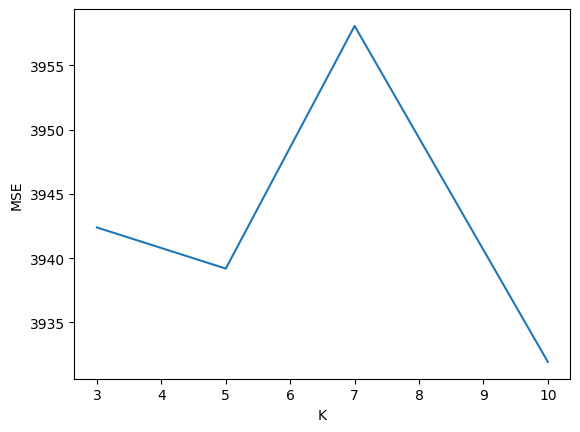

In [ ]:
plt.plot(k_values,mean_mse)
plt.xlabel("K")
plt.ylabel("MSE")
plt.show()


In [ ]:
print("Model training complete!")
print(f"Slope (m): {model.coef_}")
print(f"Intercept (c): {model.intercept_:.2f}")


Model training complete!
Slope (m): [    5.33090312  -235.78389174   500.4856749    275.28785623
 -1016.96672502   637.33668394   186.67545657   210.32623651
   878.43250988    82.29802939]
Intercept (c): 154.02


In [ ]:
from sklearn.linear_model import LinearRegression

# Instantiate and fit the single-feature model
model_single = LinearRegression()
model_single.fit(X_bmi, y_target)

# Explicitly assign Theta 0 and Theta 1
theta_0 = model_single.intercept_
theta_1 = model_single.coef_[0]  # Grab the first element from the array

print("--- Simple Linear Regression Parameters ---")
print(f"Theta 0 (Intercept) : {theta_0:.4f}")
print(f"Theta 1 (BMI Slope) : {theta_1:.4f}")


--- Simple Linear Regression Parameters ---
Theta 0 (Intercept) : 152.1335
Theta 1 (BMI Slope) : 949.4353


In [ ]:
from sklearn.linear_model import Ridge, Lasso
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split

# Load data
dataset1 = load_diabetes()
X_train, X_test, y_train, y_test = train_test_split(dataset1.data, dataset1.target, test_size=0.2, random_state=42)

# 1. Train Ridge (L2 Penalty)
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_bmi,y_target)

# 2. Train Lasso (L1 Penalty)
lasso_model = Lasso(alpha=0.1)
lasso_model.fit(X_bmi, y_target)



Lasso(alpha=0.1)

In [ ]:
from sklearn.linear_model import LinearRegression
import pandas as pd

# Train standard Linear Regression for comparison
lr = LinearRegression().fit(X_train, y_train)
ridge = Ridge(alpha=1.0).fit(X_train, y_train)
lasso = Lasso(alpha=0.1).fit(X_train, y_train)

# Put the theta coefficients into a table
coef_df = pd.DataFrame({
    'Feature': dataset1.feature_names,
    'Linear Reg (θ)': lr.coef_,
    'Ridge (θ)': ridge.coef_,
    'Lasso (θ)': lasso.coef_
})

print(coef_df.to_string(index=False, formatters={
    'Linear Reg (θ)': '{:,.2f}'.format,
    'Ridge (θ)': '{:,.2f}'.format,
    'Lasso (θ)': '{:,.2f}'.format
}))


Feature Linear Reg (θ) Ridge (θ) Lasso (θ)
    age          37.90     45.37      0.00
    sex        -241.96    -76.67   -152.66
    bmi         542.43    291.34    552.70
     bp         347.70    199.00    303.37
     s1        -931.49     -0.53    -81.37
     s2         518.06    -28.58     -0.00
     s3         163.42   -144.51   -229.26
     s4         275.32    119.26      0.00
     s5         736.20    230.22    447.92
     s6          48.67    112.15     29.64


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso

# 1. Split your single-feature data into Train and Test sets
X_train, X_test, y_train, y_test = train_test_split(
    X_bmi,
    y_target,
    test_size=0.2,
    random_state=42
)

# 2. Instantiate all three models
# (Using a high alpha=5.0 for Ridge/Lasso to make the shrinking effect easy to see)
lr = LinearRegression()
ridge = Ridge(alpha=1.0)
lasso = Lasso(alpha=1.0)

# 3. Fit all three models on the training data
lr.fit(X_bmi, y_target)
ridge.fit(X_bmi, y_target)
lasso.fit(X_bmi, y_target)

# 4. Extract and display the Theta parameters side-by-side
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Ridge (alpha=1.0)', 'Lasso (alpha=1.0)'],
    'Theta 0 (Intercept)': [lr.intercept_, ridge.intercept_, lasso.intercept_],
    'Theta 1 (BMI Slope)': [lr.coef_[0], ridge.coef_[0], lasso.coef_[0]]
})

print(results.to_string(index=False, formatters={
    'Theta 0 (Intercept)': '{:,.2f}'.format,
    'Theta 1 (BMI Slope)': '{:,.2f}'.format
}))


            Model Theta 0 (Intercept) Theta 1 (BMI Slope)
Linear Regression              152.13              949.44
Ridge (alpha=1.0)              152.13              474.72
Lasso (alpha=1.0)              152.13              507.44


In [ ]:
import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error

# 1. Load your data
dataset1 = load_diabetes()
X = dataset1.data
y = dataset1.target

# 2. Setup KFold (5 splits, with shuffling enabled)
kf = KFold(n_splits=5, shuffle=True, random_state=42)
model = LinearRegression()

# 3. Loop through each fold
fold_number = 1
for train_index, test_index in kf.split(X):

    # Generate the train and test subsets using the split indexes
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

    # Train the model on this specific fold's training data
    model.fit(X_train, y_train)

    # Test the model on this specific fold's testing data
    y_pred = model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)

    # Print out performance tracking for each split
    print(f"Fold {fold_number} -> Train rows: {len(X_train)} | Test rows: {len(X_test)} | MSE: {mse:.2f}")

    fold_number += 1


Fold 1 -> Train rows: 353 | Test rows: 89 | MSE: 2900.19
Fold 2 -> Train rows: 353 | Test rows: 89 | MSE: 2662.64
Fold 3 -> Train rows: 354 | Test rows: 88 | MSE: 3312.31
Fold 4 -> Train rows: 354 | Test rows: 88 | MSE: 2797.88
Fold 5 -> Train rows: 354 | Test rows: 88 | MSE: 3403.89


In [ ]:
import pandas as pd
from sklearn.metrics import mean_squared_error

# 1. Use each model's .predict method to get predictions for the test data
y_pred_lr = lr.predict(X_bmi)
y_pred_ridge = ridge.predict(X_bmi)
y_pred_lasso = lasso.predict(X_bmi)

# 2. Calculate the Mean Squared Error for all three
mse_lr = mean_squared_error(y_target, y_pred_lr)
mse_ridge = mean_squared_error(y_target, y_pred_ridge)
mse_lasso = mean_squared_error(y_target, y_pred_lasso)

# 3. Compile the calculated errors into a clean, scannable table
mse_table = pd.DataFrame({
    'Model Name': ['Linear Regression (lr)', 'Ridge Regression', 'Lasso Regression'],
    'Test MSE Score': [mse_lr, mse_ridge, mse_lasso]
})

print(mse_table.to_string(index=False, formatters={'Test MSE Score': '{:,.2f}'.format}))


            Model Name Test MSE Score
Linear Regression (lr)       3,890.46
      Ridge Regression       4,400.31
      Lasso Regression       4,332.46


In [ ]:
#homework
blood sugar level instead of bmi